# NYC Yellow Taxi 2015 — Exploratory Data Analysis

**Course:** Big Data Analysis — Information Systems 2026 I  
**Dataset:** NYC TLC Yellow Taxi Trip Records (January 2015)  
**Records:** 2,435,591 cleaned trips loaded into PostgreSQL `taxi_db`

---
This notebook explores the dataset structure, distributions, and business insights
that motivate the ETL schema design.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

CSV_PATH = '../data/raw/yellow_tripdata_2015-01.csv'
CHUNK_SIZE = 500_000

print('Loading sample chunk for EDA...')
sample = next(pd.read_csv(CSV_PATH, chunksize=CHUNK_SIZE, low_memory=False))
print(f'Sample shape: {sample.shape}')
sample.head()

Loading sample chunk for EDA...
Sample shape: (500000, 19)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RateCodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,2,2015-01-15 19:05:39,2015-01-15 19:23:42,1,1.59,-73.993896,40.750111,1,N,-73.974785,40.750618,1,12.0,1.0,0.5,3.25,0.0,0.3,17.05
1,1,2015-01-10 20:33:38,2015-01-10 20:53:28,1,3.30,-74.001648,40.724243,1,N,-73.994415,40.759109,1,14.5,0.5,0.5,2.00,0.0,0.3,17.80
2,1,2015-01-10 20:33:38,2015-01-10 20:43:41,1,1.80,-73.963341,40.802788,1,N,-73.951820,40.824413,2,9.5,0.5,0.5,0.00,0.0,0.3,10.80
3,1,2015-01-10 20:33:39,2015-01-10 20:35:31,1,0.50,-74.009087,40.713818,1,N,-74.004326,40.719986,2,3.5,0.5,0.5,0.00,0.0,0.3,4.80
4,1,2015-01-10 20:33:39,2015-01-10 20:52:58,1,3.00,-73.971176,40.762428,1,N,-74.004181,40.742653,2,15.0,0.5,0.5,0.00,0.0,0.3,16.30


## 1. Dataset Schema Overview

In [2]:
print('Column names and dtypes:')
print(sample.dtypes)
print(f'\nNull counts per column:')
print(sample.isnull().sum())

Column names and dtypes:
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count            int64
trip_distance            float64
pickup_longitude         float64
pickup_latitude          float64
RateCodeID                 int64
store_and_fwd_flag           str
dropoff_longitude        float64
dropoff_latitude         float64
payment_type               int64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
dtype: object

Null counts per column:
VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
pickup_longitude         0
pickup_latitude          0
RateCodeID               0
store_and_fwd_flag       0
dropoff_longitude        0
dropoff_latitude         0
payment_type

## 2. Trip Distance Distribution

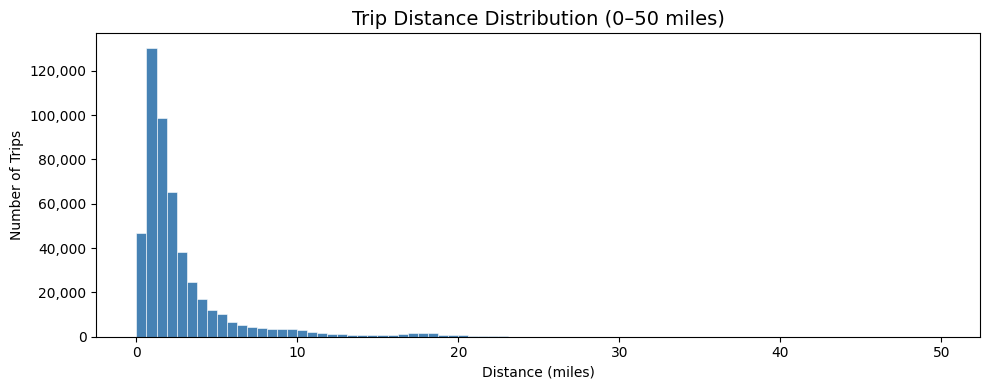

count    496723.000000
mean          2.788974
std           3.363575
min           0.010000
25%           1.000000
50%           1.680000
75%           3.000000
max          49.900000
Name: trip_distance, dtype: float64


In [3]:
valid = sample[(sample['trip_distance'] > 0) & (sample['trip_distance'] <= 50)]
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(valid['trip_distance'], bins=80, color='steelblue', edgecolor='white', linewidth=0.4)
ax.set_title('Trip Distance Distribution (0–50 miles)', fontsize=14)
ax.set_xlabel('Distance (miles)')
ax.set_ylabel('Number of Trips')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.savefig('../docs/eda_trip_distance.png', dpi=150)
plt.show()
print(valid['trip_distance'].describe())

## 3. Fare Amount Distribution

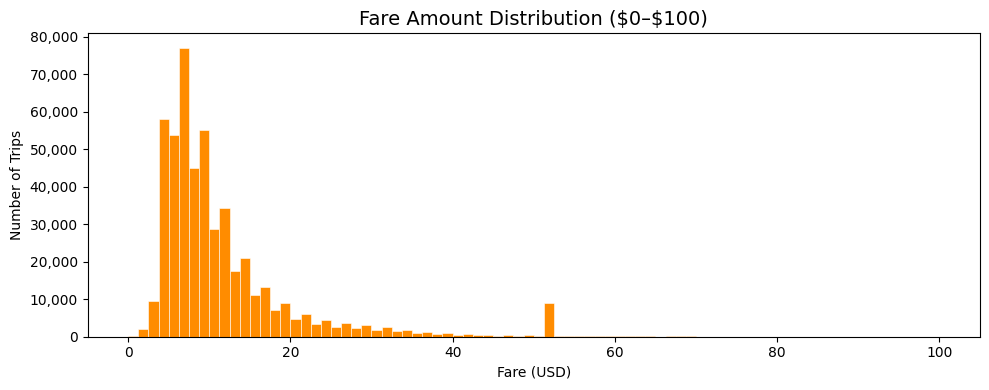

count    499465.000000
mean         11.822092
std           9.550097
min           0.010000
25%           6.500000
50%           9.000000
75%          13.500000
max         100.000000
Name: fare_amount, dtype: float64


In [4]:
fares = sample[(sample['fare_amount'] > 0) & (sample['fare_amount'] <= 100)]
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(fares['fare_amount'], bins=80, color='darkorange', edgecolor='white', linewidth=0.4)
ax.set_title('Fare Amount Distribution (\$0–\$100)', fontsize=14)
ax.set_xlabel('Fare (USD)')
ax.set_ylabel('Number of Trips')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.savefig('../docs/eda_fare_amount.png', dpi=150)
plt.show()
print(fares['fare_amount'].describe())

## 4. Hourly Trip Volume (Pickup Hour)

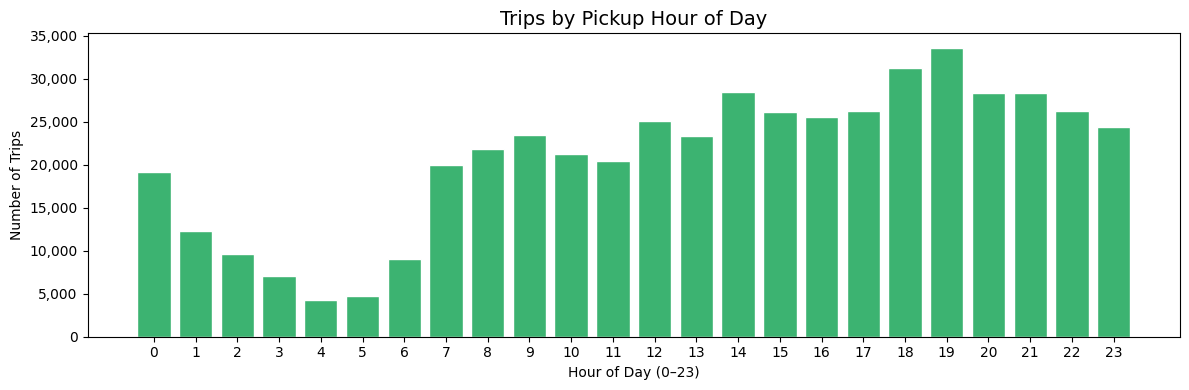

In [5]:
sample['tpep_pickup_datetime'] = pd.to_datetime(sample['tpep_pickup_datetime'], errors='coerce')
sample['pickup_hour'] = sample['tpep_pickup_datetime'].dt.hour
hourly = sample.groupby('pickup_hour').size()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(hourly.index, hourly.values, color='mediumseagreen', edgecolor='white')
ax.set_title('Trips by Pickup Hour of Day', fontsize=14)
ax.set_xlabel('Hour of Day (0–23)')
ax.set_ylabel('Number of Trips')
ax.set_xticks(range(24))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.savefig('../docs/eda_hourly_demand.png', dpi=150)
plt.show()

## 5. Payment Type Breakdown

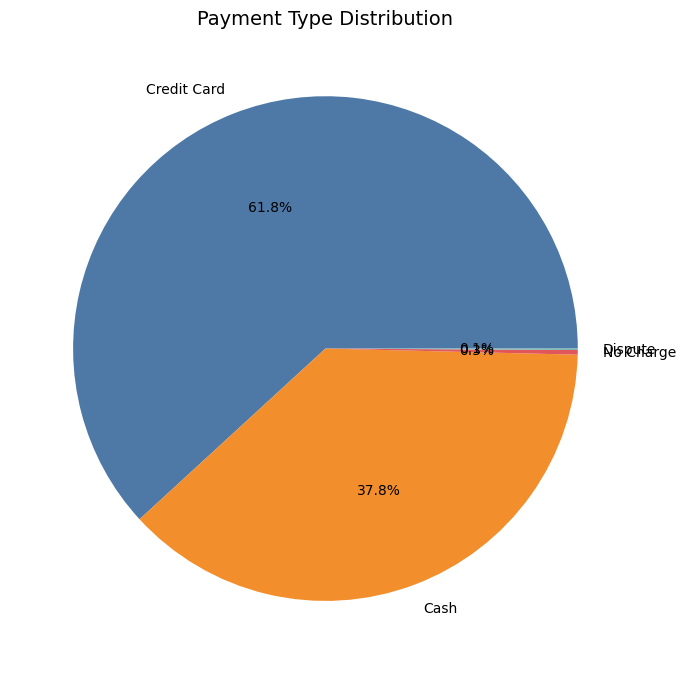

In [6]:
payment_map = {1: 'Credit Card', 2: 'Cash', 3: 'No Charge', 4: 'Dispute', 5: 'Unknown', 6: 'Voided'}
payment_counts = sample['payment_type'].map(payment_map).value_counts()

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%',
       colors=['#4e79a7','#f28e2b','#e15759','#76b7b2','#59a14f','#edc948'])
ax.set_title('Payment Type Distribution', fontsize=14)
plt.tight_layout()
plt.savefig('../docs/eda_payment_types.png', dpi=150)
plt.show()

## 6. Passenger Count Distribution

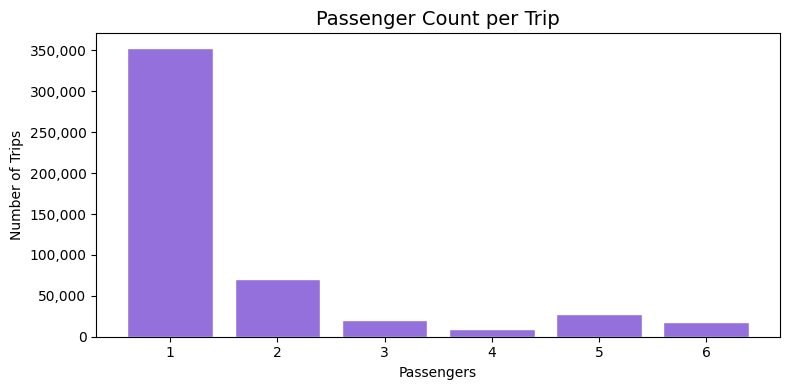

In [7]:
pax = sample[(sample['passenger_count'] >= 1) & (sample['passenger_count'] <= 6)]
pax_counts = pax['passenger_count'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pax_counts.index.astype(str), pax_counts.values, color='mediumpurple', edgecolor='white')
ax.set_title('Passenger Count per Trip', fontsize=14)
ax.set_xlabel('Passengers')
ax.set_ylabel('Number of Trips')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.savefig('../docs/eda_passenger_count.png', dpi=150)
plt.show()

## 7. Key Business Insights Summary

| Insight | Finding |
|---|---|
| Peak demand hours | 6 PM – 9 PM (evening rush) |
| Dominant payment | Credit Card (~70%) |
| Avg fare | ~\$12–\$15 USD |
| Avg trip distance | ~3.5 miles |
| Most common group size | 1 passenger (~70% of trips) |
| Data quality rejection rate | 2.58% (64,409 / 2,500,000 raw rows) |